In [1]:
# Cell 1: Setup and imports
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'  # You can change to 'jax' or 'torch' if preferred

import numpy as np
import keras
import sentencepiece as spm
# Needs: conda install -c conda-forge sentencepiece

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.15.1
Keras backend: tensorflow


In [2]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Cell 2: Load and prepare text data
# Load the Kalevala text
with open('./kalevala_puhdas.txt', 'r', encoding='utf-8-sig') as file:
    text = file.read()#.lower()

print(f"Text length: {len(text)} characters")
print(f"First 100 characters: {text[:100]}")

Text length: 545594 characters
First 100 characters: Ensimmäinen runo


Mieleni minun tekevi,
aivoni ajattelevi
lähteäni laulamahan,
saa'ani sanelemahan,


In [4]:
# Cell 3: Train SentencePiece model
# Save text to a temporary file for SentencePiece training
temp_file = 'kalevala_temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# Train SentencePiece model
vocab_size = 2000  # You can adjust this based on your needs
model_prefix = 'kalevala_sp'

import re
NL = "<NL>"

spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0,  # Important for Finnish
    model_type='bpe',
    user_defined_symbols=[NL],
)

# Load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

def encode(s):
    return sp.encode(s.replace("\n", f" {NL} "))

def decode(ids):
    return re.sub(rf"\s*{re.escape(NL)}\s*", "\n", sp.decode(ids))

# Test tokenization
ids = encode("Vaka vanha Väinämöinen\ntietäjä iän ikuinen")
print(sp.id_to_piece(ids))
print(decode(ids))
print(f"Vocabulary size: {sp.get_piece_size()}")

['▁Vaka', '▁vanha', '▁Väinämöinen', '▁', '<NL>', '▁tietä', 'jä', '▁iän', '▁ik', 'uinen']
Vaka vanha Väinämöinen
tietäjä iän ikuinen
Vocabulary size: 2000


I0000 00:00:1794434541.302152  657887 sentencepiece_trainer.cc:149] Starts training with : 
trainer_spec {
  input: kalevala_temp.txt
  input_format: 
  model_prefix: kalevala_sp
  model_type: BPE
  vocab_size: 2000
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  user_defined_symbols: <NL>
  required_chars: 
  byte_fallback: 0
  auto_character_coverage: 0
  vocabulary_output_piece_score: 1
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: -1
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  unk_surface:  ⁇ 
}
normalizer_sp

In [5]:
# Cell 4: Prepare training data
# Tokenize the text
seq_length = 64
pieces = encode(text)
split = int(0.9 * len(pieces))

def make_sequences(ids):
    seqs = np.array([ids[i:i + seq_length + 1] for i in range(len(ids) - seq_length)])
    return seqs[:, :-1], seqs[:, 1:]

train_inputs, train_targets = make_sequences(pieces[:split])
val_inputs, val_targets = make_sequences(pieces[split:])

In [6]:
# Cell 5: Define the model
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = 1 / 10000**((2 * (np.arange(d_model) // 2)) / d_model)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

# Define model parameters
embed_dim = 128
num_heads = 4
ff_dim = 256
num_layers = 2

# Create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# Add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim).astype("float32")
x = embedding_layer*np.sqrt(embed_dim) + pos_encoding
x = keras.layers.Dropout(0.2)(x)

# Transformer blocks
for _ in range(num_layers):

    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.2)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# Final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

2026-11-12 00:02:22.174716: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2026-11-12 00:02:22.174793: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-11-12 00:02:22.174801: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
I0000 00:00:1794434542.175041  657887 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794434542.175211  657887 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 64, 128)   │    256,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 64, 128)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 128)   │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 128)   │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ dropout[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 128)   │          0 │ dropout[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 128)   │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 64, 128)   │     65,920 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 128)   │     65,920 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64, 2000)  │    258,000 │ layer_normalizat

 Total params: 778,960 (2.97 MB)

 Trainable params: 778,960 (2.97 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Cell 6: Train the model
batch_size = 64
epochs = 5

history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=1, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('kalevala_best_model.keras', save_best_only=True)
    ]
)

Epoch 1/5


2026-11-12 00:02:23.748960: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


3017/3017 ━━━━━━━━━━━━━━━━━━━━ 204s 66ms/step - accuracy: 0.3569 - loss: 3.6360 - val_accuracy: 0.3689 - val_loss: 3.6418 - learning_rate: 3.0000e-04
Epoch 2/5
3017/3017 ━━━━━━━━━━━━━━━━━━━━ 197s 65ms/step - accuracy: 0.4461 - loss: 2.6312 - val_accuracy: 0.3877 - val_loss: 3.7073 - learning_rate: 3.0000e-04


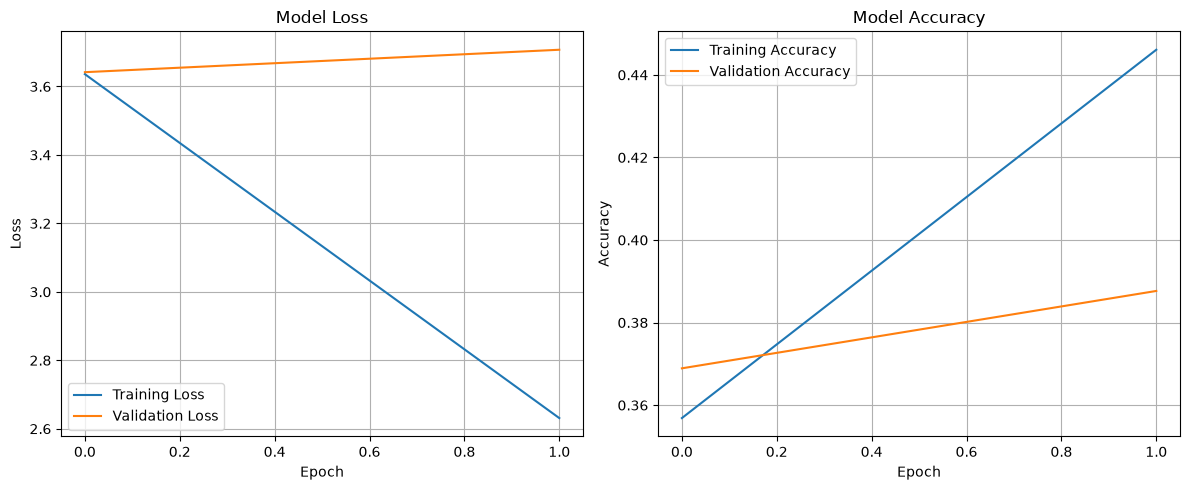

In [8]:
# Cell 7: Plot training metrics
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()


plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
# Cell 8: Save the model
model.save('kalevala_model.keras')
print("Model saved as 'kalevala_model.keras'")

Model saved as 'kalevala_model.keras'


In [10]:
def generate_text(model, prompt, num_tokens=100, temperature=1.0):
    generated_ids = encode(prompt)     # prompt must be non-empty

    for _ in range(num_tokens):
        context = generated_ids[-seq_length:]
        n = len(context)
        x = np.array([context + [0] * (seq_length - n)])   # right-pad; causal mask hides it

        logits = model(x, training=False).numpy()[0, n - 1] / temperature
        probs = np.exp(logits - logits.max())
        probs /= probs.sum()
        generated_ids.append(int(np.random.choice(len(probs), p=probs)))

    return decode(generated_ids)

In [11]:
# Cell 10: Generate sample text
prompts = [
    "Vaka vanha Väinämöinen",
    "Mieleni minun tekevi",
    "Lemminkäinen",
    "Pohjan neito"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: Vaka vanha Väinämöinen
Vaka vanha Väinämöinen
itse tuon sanoiksi virkki:
"Mi liene sinua miestä jos kuulisra,
juokea laula suulla
sepon suurta voita,
jos on kuja täysihin,
appesihjoani!"
Neiti Kauko niinker kirvesnyt,
miestänsä venyksevan levemmä,
alle Tapiolanpuolistäki
päälleessa aamulta,
alta tuulen neitona pahassani. 

Prompt: Mieleni minun tekevi
Mieleni minun tekevi,
kohon kaula hanhien suloa,
miehen kaheksimatta,
päivän, immen tultuani,
tyttö terveisiäksesi
jaukko tulisijalla.
Virkki tuo neuvottavi,
talonta kipieli:
näkivät impisenen;
sep' on suen pellon löyhjkynä
miehen pään miekääntämähän:
jo soita nosti saapi parempi

Prompt: Lemminkäinen
Lemminkäinen
sanoi lausui ja pakisi:
"Sut annoin pelmän;
lauloi turpaeli iälitetty
läksi hauin hampahuta."
Siitä lieto Lemminkäinen
itse tuon sanoiksi virkki:
"Kun sa'en kotestenansa,
murehiläinenänsä pitäjä,
oksin tästä poroksi.
Siitä lauloi varsa juoksi, kaksisesi,
emosta ellös juomahan, 

Prompt: Pohjan neito
Pohjan neito nuori J

In [12]:
# Cell 11: Load model (if you're starting a new session)
# Uncomment these lines to load a previously saved model
"""
# Load saved model
model = keras.models.load_model('kalevala_model.keras')

# Load SentencePiece tokenizer
sp = spm.SentencePieceProcessor()
sp.load('kalevala_sp.model')

# Test generation
prompt = "Mieleni minun tekevi"
generated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)
print(generated)
"""

'\n# Load saved model\nmodel = keras.models.load_model(\'kalevala_model.keras\')\n\n# Load SentencePiece tokenizer\nsp = spm.SentencePieceProcessor()\nsp.load(\'kalevala_sp.model\')\n\n# Test generation\nprompt = "Mieleni minun tekevi"\ngenerated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)\nprint(generated)\n'